# 01 — Tabular baseline: Deotte's XGB with "magic"

Re-implementation of Chris Deotte's [XGB Fraud with Magic 0.9600](https://www.kaggle.com/cdeotte/xgb-fraud-with-magic-0-9600)
(part of the 1st-place solution). The feature code lives in `src/features.py` so later steps can
reuse it. This notebook runs the whole step: load → features → train XGB95 and XGB96 → compare.

| Model | Features | Deotte's reported AUC (his 75/25 split) |
|---|---|---|
| **XGB95** | base + frequency / combined / group encodings (216) | 0.9363 |
| **XGB96** | XGB95 + "magic" per-client UID aggregations (263) | 0.9472 |

**Runtime on this Mac (CPU, 8 cores):** features about 20 s; each model 3–5 min.
Kernel: *Python (ieee-cis-fraud)*. Needs `data/processed/*.parquet` (`python -m src.data`).

In [2]:
import sys; sys.path.insert(0, '..')
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

from src.data import load
from src.features import build_features
from src.validation import time_split
print('xgboost', xgb.__version__)

xgboost 3.4.2


## 1. Load the cached data

In [3]:
train, test = load('train'), load('test')
train.shape, test.shape

((590540, 435), (506691, 434))

## 2. Normalizing D columns
`D15` counts **days since some past event** of the card (e.g. account opened). Two ways to express it:
- **delta** (original): *how many days ago* did the event happen? This is the card's age, and it
  grows by 1 every day for the same card.
- **date** (normalized): *on which day* did it happen? `D15 - day` = minus the event date. This is
  **constant for the same card**.

Trees split on one column at a time and can't compute `day - D15` themselves, so we hand them the
date. The "age" signal isn't lost: D1, D2, D3, D5, D9 stay raw.

**How to read the 2D histograms below** (all train + test rows; colour = transactions per cell, log scale):
- The densest band is `D15 = 0` (event on the same day as the transaction). It is flat at 0 on
  the left and becomes the diagonal `-day` on the right: the same rows, re-expressed as a date.
- A **horizontal line** on the right = many transactions sharing one event date. They aren't single
  clients: e.g. ~1,000 different cards have their event on day 93. On the left, the same rows
  rise as a diagonal, because their age grows daily.
- **Range drift doesn't go away.** On the right, test extends below train's minimum: about half of
  test rows have an event date *after* train ended (new cards). On the left, the dense band's top
  edge rises with time instead. The next cell shows what normalization actually buys.

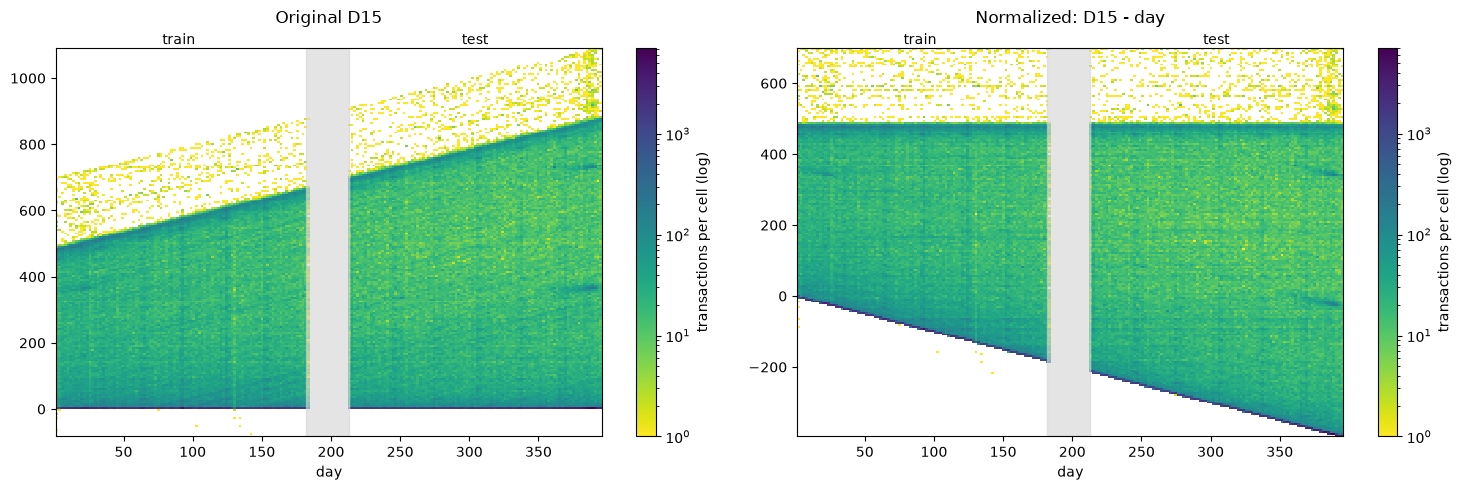

In [4]:
from matplotlib.colors import LogNorm

# All rows of train AND test (test = days 213-395) so we can see the drift into the future.
both = pd.concat([train[['TransactionDT', 'D15']], test[['TransactionDT', 'D15']]]).dropna()
day_float = both.TransactionDT / 86400
panels = [('Original D15', both.D15),
          ('Normalized: D15 - day', both.D15 - day_float)]

fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for a, (title, y) in zip(ax, panels):
    # 2D histogram: each cell's colour = number of transactions in it.
    # Log colour scale, because a few cells hold thousands of rows and most hold a handful.
    h = a.hist2d(day_float, y, bins=(200, 200), norm=LogNorm(), cmap='viridis_r', cmin=1)
    fig.colorbar(h[3], ax=a, label='transactions per cell (log)')
    a.axvspan(182, 213, color='lightgrey', alpha=0.6)   # gap between train and test
    a.text(90, 1.01, 'train', transform=a.get_xaxis_transform(), ha='center')
    a.text(304, 1.01, 'test', transform=a.get_xaxis_transform(), ha='center')
    a.set_title(title, pad=18); a.set_xlabel('day')
plt.tight_layout(); plt.show()

### What normalization buys: a stable value *per client*
Group transactions by an approximate client id (`card1 + addr1 + first-use date from D1`) and compare
the same clients in train vs test, and the spread within a client. Normalized D15 barely moves
for a client, while raw D15 moves by months. That per-client constancy is what makes
`D15_uid_mean` / `D15_uid_std` useful: a std near 0 means a consistent client, and a large value
flags a transaction that doesn't fit its group.

In [5]:
def d15_views(d):
    day_f = d.TransactionDT / 86400
    return pd.DataFrame({
        'client': d.card1.astype(str) + '_' + d.addr1.astype(str) + '_' + np.floor(day_f - d.D1).astype(str),
        'original': d.D15,
        'normalized': d.D15 - day_f,
    }).dropna()

a, b = d15_views(train), d15_views(test)
rows = []
for col in ['original', 'normalized']:
    same = (a.groupby('client')[col].median().rename('tr').to_frame()
              .join(b.groupby('client')[col].median().rename('te'), how='inner'))
    shift = (same.te - same.tr).abs()
    spread = a.groupby('client')[col].agg(['std', 'size']).query('size >= 5')['std']
    rows.append({'D15 version': col,
                 'clients in train & test': len(same),
                 'median shift train->test (days)': round(shift.median(), 1),
                 'clients shifting <= 1 day': f'{(shift <= 1).mean():.0%}',
                 'median spread within client (train)': round(spread.median(), 2)})
print(f"test rows outside train range: original {(b.original > a.original.max()).mean():.1%}, "
      f"normalized {(b.normalized < a.normalized.min()).mean():.1%}")
pd.DataFrame(rows)

test rows outside train range: original 0.2%, normalized 51.7%


,D15 version,clients in train & test,median shift train->test (days),clients shifting <= 1 day,median spread within client (train)
0,original,24655,174.5,1%,43.849998
1,normalized,24655,0.2,79%,0.240000


## 3. Build features
`build_features` (see `src/features.py`) works on train+test combined. It label-encodes strings,
sets NaN to -1, normalizes D columns, then adds:
- **frequency encoding**: how common a value is (rare cards/addresses behave differently)
- **combined columns**: `card1_addr1`, `card1_addr1_P_emaildomain`
- **group aggregations**: e.g. mean/std of `TransactionAmt` per `card1`
- **magic (XGB96 only)**: the same kind of aggregations per **UID**

These use train *and* test feature values but **never labels**, so nothing leaks.

In [6]:
t = time.time()
df, f95, f96 = build_features(train, test)
print(f'{time.time()-t:.0f}s  ->  XGB95: {len(f95)} features, XGB96: {len(f96)} features')
print('magic features:', [c for c in f96 if c not in f95])

14s  ->  XGB95: 216 features, XGB96: 263 features
magic features: ['uid_FE', 'TransactionAmt_uid_mean', 'TransactionAmt_uid_std', 'D4_uid_mean', 'D4_uid_std', 'D9_uid_mean', 'D9_uid_std', 'D10_uid_mean', 'D10_uid_std', 'D15_uid_mean', 'D15_uid_std', 'C1_uid_mean', 'C2_uid_mean', 'C4_uid_mean', 'C5_uid_mean', 'C6_uid_mean', 'C7_uid_mean', 'C8_uid_mean', 'C9_uid_mean', 'C10_uid_mean', 'C11_uid_mean', 'C12_uid_mean', 'C13_uid_mean', 'C14_uid_mean', 'M1_uid_mean', 'M2_uid_mean', 'M3_uid_mean', 'M4_uid_mean', 'M5_uid_mean', 'M6_uid_mean', 'M7_uid_mean', 'M8_uid_mean', 'M9_uid_mean', 'uid_P_emaildomain_ct', 'uid_dist1_ct', 'uid_DT_M_ct', 'uid_id_02_ct', 'uid_cents_ct', 'C14_uid_std', 'uid_C13_ct', 'uid_V314_ct', 'uid_V127_ct', 'uid_V136_ct', 'uid_V309_ct', 'uid_V307_ct', 'uid_V320_ct', 'outsider15']


## 4. The magic: UID ≈ one client
`uid = card1_addr1 + floor(day - D1)`. `D1` is "days since the card was first used", so `day - D1`
is the card's first-use date, the same for all its transactions.

Fraud is a property of **clients**: once a card is used for fraud, its later transactions are
labelled fraud too. Check: within a UID, is the label almost always constant?

In [7]:
t = df[~df.is_test]
g = t.groupby('uid').isFraud.agg(['size', 'mean'])
multi = g[g['size'] > 1]
print(f"train UIDs with >1 transaction: {len(multi):,}")
print(f"share whose label is constant (all 0 or all 1): {((multi['mean']==0)|(multi['mean']==1)).mean():.3f}")
print(f"transactions per UID: {g['size'].mean():.2f}   per card1: {t.groupby('card1').size().mean():.1f}")

train UIDs with >1 transaction: 92,609
share whose label is constant (all 0 or all 1): 0.966
transactions per UID: 2.71   per card1: 43.6


The model never sees `uid` itself (in test it's just a meaningless ID). It gets aggregates like
`TransactionAmt_uid_mean`, `D15_uid_std`, `uid_P_emaildomain_ct` ("what do this client's
transactions look like?"), so a tree can group a client's transactions together.

## 5. Validation split
Choose one:
- `'deotte'`: first 75% of train rows → last 25% (compare with his 0.9363 / 0.9472)
- `'ours'`: `src/validation.py`, train day < 148, 7-day gap, validate day ≥ 155. **All later steps use this one.**

In [9]:
SPLIT = 'ours'   # or 'deotte'

labelled = df[~df.is_test].reset_index(drop=True)
if SPLIT == 'deotte':
    n = len(labelled)
    tr = np.arange(n) < 3 * n // 4          # rows are sorted by time
    va = ~tr
else:
    tr, va = (m.to_numpy() for m in time_split(train))
y = labelled['isFraud']
print(f"train {tr.sum():,} rows (fraud {y[tr].mean():.4f}) | val {va.sum():,} rows (fraud {y[va].mean():.4f})")

train 490,555 rows (fraud 0.0351) | val 78,542 rows (fraud 0.0353)


## 6. Train
Deotte's parameters; only `tree_method='gpu_hist'` → `'hist'` (CPU). `missing=-1` tells XGBoost our
-1 means NaN. Like the original, the validation set is also used for early stopping, which makes
the AUC slightly optimistic. That's fine for *comparing* models, since both get the same treatment.

In [10]:
PARAMS = dict(n_estimators=2000, max_depth=12, learning_rate=0.02, subsample=0.8,
              colsample_bytree=0.4, missing=-1, eval_metric='auc', early_stopping_rounds=100,
              tree_method='hist', n_jobs=8, random_state=42)

def train_eval(features, name):
    t = time.time()
    clf = xgb.XGBClassifier(**PARAMS)
    clf.fit(labelled.loc[tr, features], y[tr],
            eval_set=[(labelled.loc[va, features], y[va])], verbose=200)
    auc = roc_auc_score(y[va], clf.predict_proba(labelled.loc[va, features])[:, 1])
    print(f'{name}: val AUC = {auc:.4f}  (best iteration {clf.best_iteration}, {(time.time()-t)/60:.1f} min)')
    return clf, auc

In [11]:
clf95, auc95 = train_eval(f95, 'XGB95')

[0]	validation_0-auc:0.82512
[200]	validation_0-auc:0.93129
[400]	validation_0-auc:0.93716
[600]	validation_0-auc:0.93722
[623]	validation_0-auc:0.93706
XGB95: val AUC = 0.9375  (best iteration 523, 1.8 min)


In [12]:
clf96, auc96 = train_eval(f96, 'XGB96')

[0]	validation_0-auc:0.84331
[200]	validation_0-auc:0.94428
[400]	validation_0-auc:0.94830
[568]	validation_0-auc:0.94813
XGB96: val AUC = 0.9485  (best iteration 468, 2.4 min)


## 7. Compare

In [13]:
pd.DataFrame({'model': ['XGB95', 'XGB96'], 'split': SPLIT,
              'n_features': [len(f95), len(f96)], 'val_auc': [auc95, auc96]})

,model,split,n_features,val_auc
0,XGB95,ours,216,0.937537
1,XGB96,ours,263,0.948468


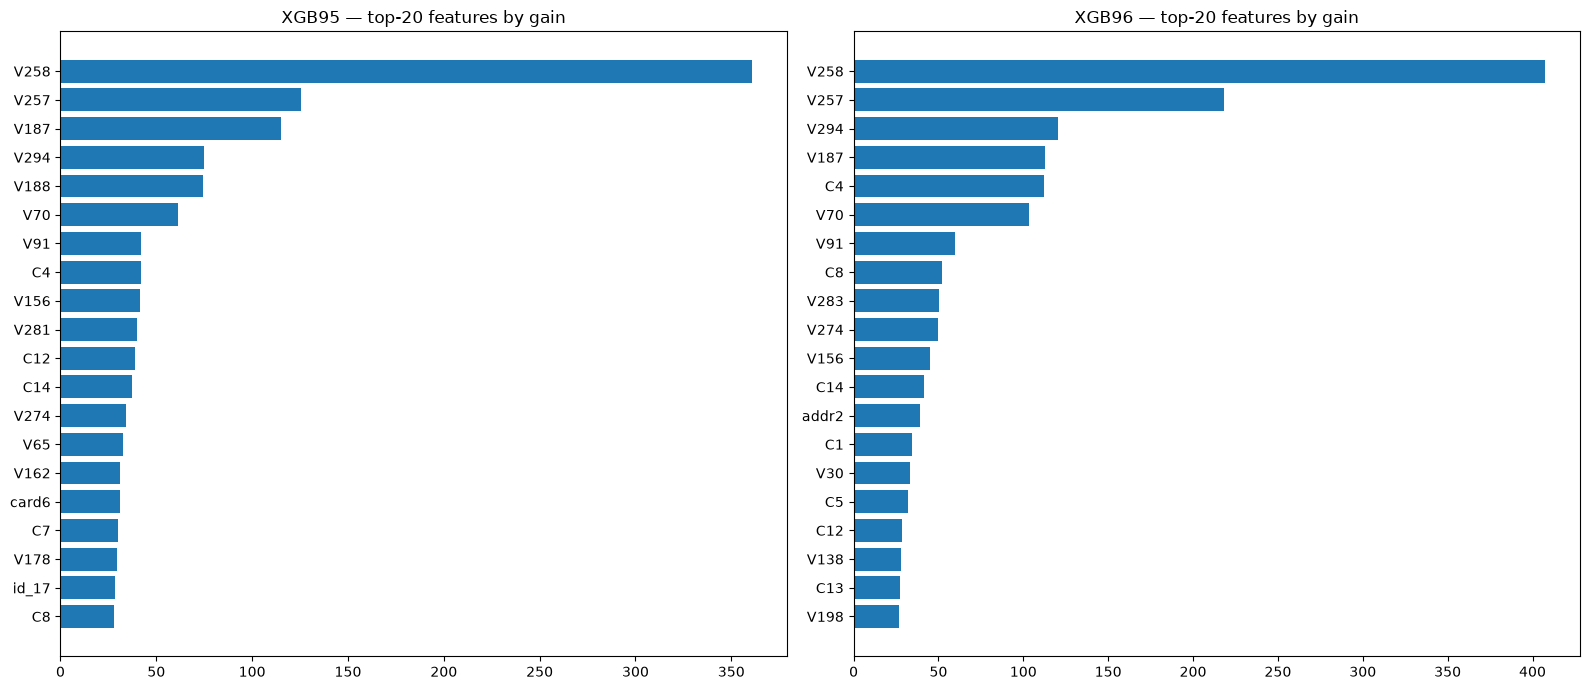

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (clf, feats, name) in zip(ax, [(clf95, f95, 'XGB95'), (clf96, f96, 'XGB96')]):
    gain = pd.Series(clf.get_booster().get_score(importance_type='gain')).reindex(feats).fillna(0)
    top = gain.sort_values().tail(20)
    a.barh(top.index, top.values); a.set_title(f'{name} — top-20 features by gain')
plt.tight_layout(); plt.show()

## 8. Reference results
`python -m src.train_baseline` runs both models on both splits and saves
`results/01_baseline_runs.json`. Your numbers above should be within about ±0.001 of these
(XGBoost's subsampling makes runs vary slightly).

In [15]:
import json, os
p = '../results/01_baseline_runs.json'
pd.DataFrame(json.load(open(p))) if os.path.exists(p) else 'not run yet'

,model,split,n_features,train_rows,val_rows,val_auc,best_iteration,train_minutes,xgboost
0,XGB95,deotte,216,442905,147635,0.93617,550,2.7,3.4.2
1,XGB96,deotte,263,442905,147635,0.94824,487,3.8,3.4.2
2,XGB95,ours,216,490555,78542,0.93754,523,2.1,3.4.2
3,XGB96,ours,263,490555,78542,0.94847,468,2.9,3.4.2
